# 01 · Data, cleaning en EDA

**Gemaakt door:** Brent Van Gelder, met assistentie van GPT-5.6-Luna  
**Doel:** de volledige dataflow in één uitlegbaar notebook uitvoeren: downloaden en auditen, raw data voorbereiden, cleaning controleren en de EDA maken.

Voer dit notebook van boven naar beneden uit vanaf de repository-root. De voorbereiding staat bewust vóór de EDA, omdat de EDA `data/processed/trips.parquet` gebruikt. `RUN_DOWNLOAD` blijft standaard `False`, net als in het oorspronkelijke downloadnotebook; zet dit alleen op `True` wanneer de officiële brondata opnieuw moeten worden opgehaald. De inhoudelijke codecellen zijn ongewijzigd overgenomen uit de bestaande, reeds uitgevoerde notebooks.


In [1]:
# Maak lokale projectimports betrouwbaar in VS Code, JupyterLab en nbconvert.
from pathlib import Path
import sys

PROJECT_ROOT = next(
    (
        path
        for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "pyproject.toml").exists() and (path / "src").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Projectroot niet gevonden; open de map Brent als VS Code-workspace.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print(f"Projectroot: {PROJECT_ROOT}")

Projectroot: C:\Users\brent\3ACS01\Deep Learning\CloudAI-Challenge\citi_bike\Brent


# Deel 1 · Download en data-audit

_Bron: `01_download_and_audit.ipynb`_


## Keuze van periode

De standaardrun gebruikt de volledige gepubliceerde historie vanaf juni 2013. De
downloader ontdekt de nieuwste officiële publicatie automatisch. Zo worden alle
jaren en seizoenen gebruikt zonder jaarlijks een einddatum in de code te wijzigen.

In [2]:
from pathlib import Path
import json
import pandas as pd
from src.config import DEFAULT_END_MONTH, DEFAULT_START_MONTH, RAW_DIR, WEATHER_PATH
from src.data.download import download_range
from src.data.weather import download_hourly_weather

START_MONTH = DEFAULT_START_MONTH
END_MONTH = DEFAULT_END_MONTH
RUN_DOWNLOAD = False    # zet bewust op True; download kan meerdere GB zijn
if RUN_DOWNLOAD:
    download_range(START_MONTH, END_MONTH)
    download_hourly_weather(START_MONTH, END_MONTH, WEATHER_PATH)

## Controle van provenance

Het manifest maakt elke bronfile controleerbaar met URL, grootte en SHA-256.

In [3]:
manifest_path = RAW_DIR / "manifest.json"
if not manifest_path.exists():
    print("Nog geen manifest. Zet RUN_DOWNLOAD=True en voer de vorige cel uit.")
else:
    manifest = pd.DataFrame(json.loads(manifest_path.read_text()))
    display(manifest)
    print(f"Totaal: {manifest['bytes'].sum() / 1e9:.2f} GB")
    assert manifest["sha256"].str.len().eq(64).all()

,key,period,first_month,last_month,bytes,last_modified,url,file,sha256,status,recorded_at_utc
0,2013-citibike-tripdata.zip,2013,201306,201312,329797836,2024-02-22T14:26:20.000Z,https://s3.amazonaws.com/tripdata/2013-citibik...,2013-citibike-tripdata.zip,4f9936239e741078da5c64206702240d15c5d57fdba2c1...,reused,2026-10-12T12:52:49.217988+00:00
1,2014-citibike-tripdata.zip,2014,201401,201412,224608955,2024-02-22T14:26:20.000Z,https://s3.amazonaws.com/tripdata/2014-citibik...,2014-citibike-tripdata.zip,0c8468df81be760a87605cf6f83d89b5c30714632b0f74...,reused,2026-10-12T12:52:52.101135+00:00
2,2015-citibike-tripdata.zip,2015,201501,201512,276450868,2024-02-22T14:26:20.000Z,https://s3.amazonaws.com/tripdata/2015-citibik...,2015-citibike-tripdata.zip,b6085d17d86d3f156bec59e76420a9d24a5fac83981a16...,reused,2026-10-12T12:52:55.673818+00:00
3,2016-citibike-tripdata.zip,2016,201601,201612,435167562,2024-02-22T14:26:20.000Z,https://s3.amazonaws.com/tripdata/2016-citibik...,2016-citibike-tripdata.zip,3f2a47babfe48f1397247861867bd1a6057f62d4564d12...,reused,2026-10-12T12:53:01.193200+00:00
4,2017-citibike-tripdata.zip,2017,201701,201712,557126574,2024-02-22T14:26:20.000Z,https://s3.amazonaws.com/tripdata/2017-citibik...,2017-citibike-tripdata.zip,d71ee823b0ef9fadf948a75b52ace6f6a5a363202f34e5...,reused,2026-10-12T12:53:08.181377+00:00
5,2018-citibike-tripdata.zip,2018,201801,201812,1337685504,2024-02-22T14:26:20.000Z,https://s3.amazonaws.com/tripdata/2018-citibik...,2018-citibike-tripdata.zip,91f39eda364531181bb2b983afb69e6875106e5032c6d8...,reused,2026-10-12T12:53:24.780722+00:00
6,2019-citibike-tripdata.zip,2019,201901,201912,858704099,2024-02-22T14:52:46.000Z,https://s3.amazonaws.com/tripdata/2019-citibik...,2019-citibike-tripdata.zip,2e86870f91f51ea7f3a5209cba159e043f0507d9bae801...,reused,2026-10-12T12:53:34.704941+00:00
7,2020-citibike-tripdata.zip,2020,202001,202012,751199232,2024-07-31T18:18:37.000Z,https://s3.amazonaws.com/tripdata/2020-citibik...,2020-citibike-tripdata.zip,32f7d883b6a7afc505bde6f4d15b505efe85c691c9117b...,reused,2026-10-12T12:53:44.841829+00:00
8,2021-citibike-tripdata.zip,2021,202101,202112,1074415437,2024-08-13T12:47:01.000Z,https://s3.amazonaws.com/tripdata/2021-citibik...,2021-citibike-tripdata.zip,20c5cb71bc2525e2ddf4a1051981cb5c1b6761ab6ec042...,reused,2026-10-12T12:53:57.559440+00:00
9,2022-citibike-tripdata.zip,2022,202201,202212,1231367136,2024-07-31T18:18:37.000Z,https://s3.amazonaws.com/tripdata/2022-citibik...,2022-citibike-tripdata.zip,6ef907ab1737aba619d09549a1ac62604da1b5190c7def...,reused,2026-10-12T12:54:12.113375+00:00


Totaal: 32.54 GB


## Schema-audit zonder alles in geheugen te laden

We lezen alleen de headers en vergelijken kolommen per CSV-lid.

In [4]:
from zipfile import ZipFile

schemas = []
for path in sorted(RAW_DIR.glob("*-citibike-tripdata.zip")):
    with ZipFile(path) as archive:
        for member in archive.namelist():
            is_csv = member.lower().endswith(".csv")
            is_macos_metadata = "__MACOSX/" in member or Path(member).name.startswith("._")
            if is_csv and not is_macos_metadata:
                with archive.open(member) as handle:
                    columns = pd.read_csv(handle, nrows=0).columns.tolist()
                schemas.append({"archive": path.name, "member": member, "columns": columns})
display(pd.DataFrame(schemas))

,archive,member,columns
0,2013-citibike-tripdata.zip,2013-citibike-tripdata/201309-citibike-tripdat...,"[tripduration, starttime, stoptime, start stat..."
1,2013-citibike-tripdata.zip,2013-citibike-tripdata/201311-citibike-tripdat...,"[tripduration, starttime, stoptime, start stat..."
2,2013-citibike-tripdata.zip,2013-citibike-tripdata/201307-citibike-tripdat...,"[tripduration, starttime, stoptime, start stat..."
3,2013-citibike-tripdata.zip,2013-citibike-tripdata/201308-citibike-tripdat...,"[tripduration, starttime, stoptime, start stat..."
4,2013-citibike-tripdata.zip,2013-citibike-tripdata/201306-citibike-tripdat...,"[tripduration, starttime, stoptime, start stat..."
...,...,...,...
282,202609-citibike-tripdata.zip,202609-citibike-tripdata_4.csv,"[ride_id, rideable_type, started_at, ended_at,..."
283,202609-citibike-tripdata.zip,202609-citibike-tripdata_5.csv,"[ride_id, rideable_type, started_at, ended_at,..."
284,202609-citibike-tripdata.zip,202609-citibike-tripdata_1.csv,"[ride_id, rideable_type, started_at, ended_at,..."
285,202609-citibike-tripdata.zip,202609-citibike-tripdata_2.csv,"[ride_id, rideable_type, started_at, ended_at,..."


## Besluit

Het downloadscript faalt expliciet bij corrupte ZIP's en schrijft pas na succesvolle
validatie. Schema-afwijkingen worden hier zichtbaar voordat cleaning start. Noteer in
de definitieve versie de gedownloade periode, omvang en eventuele afwijkingen.

# Deel 2 · Definitieve datavoorbereiding

_Bron: `03_prepare_data.ipynb`_


## Eén bron van waarheid

Alle cleaningregels leven in `src/data/prepare.py`; dit notebook roept die code aan en voert acceptatiechecks uit.

In [5]:
from pathlib import Path
import json
import pandas as pd
from src.config import RAW_DIR, PROCESSED_DIR
from src.data.prepare import prepare_archives

OUTPUT = PROCESSED_DIR / "trips.parquet"
summary = prepare_archives(RAW_DIR, OUTPUT)
display(pd.Series({k: v for k, v in summary.items() if k != "chunks"}))

Processing 2013-citibike-tripdata.zip:2013-citibike-tripdata/201309-citibike-tripdata.csv


Processing 2013-citibike-tripdata.zip:2013-citibike-tripdata/201311-citibike-tripdata.csv


Processing 2013-citibike-tripdata.zip:2013-citibike-tripdata/201307-citibike-tripdata.csv


Processing 2013-citibike-tripdata.zip:2013-citibike-tripdata/201308-citibike-tripdata.csv


Processing 2013-citibike-tripdata.zip:2013-citibike-tripdata/201306-citibike-tripdata.csv


...

Processing 202609-citibike-tripdata.zip:202609-citibike-tripdata_1.csv


Processing 202609-citibike-tripdata.zip:202609-citibike-tripdata_2.csv


Processing 202609-citibike-tripdata.zip:202609-citibike-tripdata_3.csv


Wrote 327,931,287 rows to C:\Users\brent\3ACS01\Deep Learning\CloudAI-Challenge\citi_bike\Brent\data\processed\trips.parquet


created_at_utc                                     2026-10-14T11:57:34.054397+00:00
archives                                                                         44
input_rows                                                                328800493
output_rows                                                               327931287
filter_counts_are_nonexclusive                                                 True
rules                             {'duration_minutes': [1.0, 180.0], 'latitude':...
dtype: object

## Acceptatiechecks

Deze invarianten voorkomen dat schemawijzigingen stilletjes verkeerde trainingsdata opleveren.

In [6]:
import pyarrow.parquet as pq
from src.data.sample import systematic_parquet_sample

stored_rows = pq.ParquetFile(OUTPUT).metadata.num_rows
data = systematic_parquet_sample(OUTPUT, max_rows=1_000_000)
assert stored_rows == summary["output_rows"]
assert data.ride_id.is_unique
assert data.duration_minutes.between(1, 180).all()
assert data.member_casual.isin(["member", "casual"]).all()
assert data.start_lat.between(40.4, 41.1).all()
assert data.start_lng.between(-74.4, -73.5).all()
assert data.started_at.notna().all()
assert data.start_station_id.notna().all()
print(f"PASS — {len(data):,} rijen, {data.started_at.min()} t/m {data.started_at.max()}")

PASS — 999,791 rijen, 2013-06-01 00:44:23 t/m 2026-09-30 23:28:17.090000


## Outputcontract

De Parquet-data en audit worden niet gecommit vanwege omvang. Het downloadmanifest, codeversie en requirements maken reconstructie mogelijk.

# Deel 3 · EDA en cleaningcontrole

_Bron: `02_eda_and_cleaning.ipynb`_


## Laden

Notebook 03 maakt het Parquet-bestand. Voor de EDA nemen we maximaal één miljoen gelijkmatig verdeelde rijen om plots responsief te houden.

In [7]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import PROCESSED_DIR
from src.data.sample import systematic_parquet_sample

sns.set_theme(style="whitegrid")
path = PROCESSED_DIR / "trips.parquet"
trips = systematic_parquet_sample(path, max_rows=1_000_000).sort_values("started_at")
print(f"EDA-steekproef: {len(trips):,} ritten, {trips.started_at.min()} t/m {trips.started_at.max()}")
display(trips.head())

EDA-steekproef: 999,791 ritten, 2013-06-01 00:44:23 t/m 2026-09-30 23:28:17.090000


,ride_id,rideable_type,started_at,ended_at,duration_minutes,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,source_month
10819,2013-citibike-tripdata-2013-citibike-tripdata-...,unknown,2013-06-01 00:44:23,2013-06-01 00:46:00,1.616667,Willoughby Ave & Hall St,244,Emerson Pl & Myrtle Ave,354.0,40.691960,-73.965369,40.693631,-73.962236,member,201306
10820,2013-citibike-tripdata-2013-citibike-tripdata-...,unknown,2013-06-01 07:17:19,2013-06-01 07:30:41,13.366667,West Thames St,363,Christopher St & Greenwich St,358.0,40.708347,-74.017134,40.732916,-74.007114,member,201306
10821,2013-citibike-tripdata-2013-citibike-tripdata-...,unknown,2013-06-01 09:22:05,2013-06-01 09:40:52,18.783333,South St & Gouverneur Ln,315,West St & Chambers St,426.0,40.703554,-74.006702,40.717548,-74.013221,casual,201306
10822,2013-citibike-tripdata-2013-citibike-tripdata-...,unknown,2013-06-01 10:22:20,2013-06-01 10:28:33,6.216667,E 2 St & Avenue B,301,E 10 St & Avenue A,445.0,40.722174,-73.983688,40.727408,-73.981420,member,201306
10823,2013-citibike-tripdata-2013-citibike-tripdata-...,unknown,2013-06-01 11:17:07,2013-06-01 11:25:25,8.300000,Howard St & Centre St,268,Norfolk St & Broome St,311.0,40.719105,-73.999733,40.717227,-73.988021,member,201306


## Datakwaliteit

We kwantificeren ontbrekende waarden en duplicaten. Missende eindstations mogen voor ons voorspeldoel blijven bestaan; een ontbrekend startstation niet.

In [8]:
quality = pd.DataFrame({
    "dtype": trips.dtypes.astype(str),
    "missing_n": trips.isna().sum(),
    "missing_pct": trips.isna().mean().mul(100).round(2),
    "unique": trips.nunique(dropna=False),
}).sort_values("missing_pct", ascending=False)
display(quality)
print("Dubbele ride_id's:", trips.ride_id.duplicated().sum())
display(trips.duration_minutes.describe(percentiles=[.5, .9, .95, .99]).to_frame())

,dtype,missing_n,missing_pct,unique
end_station_id,string,1305,0.13,4578
end_station_name,string,1221,0.12,2793
end_lng,float64,1181,0.12,3504
end_lat,float64,1181,0.12,3531
ride_id,object,0,0.00,999791
rideable_type,string,0,0.00,3
started_at,datetime64[ns],0,0.00,999786
start_station_id,string,0,0.00,4489
start_station_name,string,0,0.00,2755
duration_minutes,float64,0,0.00,646283


Dubbele ride_id's: 0


,duration_minutes
count,999791.000000
mean,13.562795
std,12.836190
min,1.000000
50%,9.850000
90%,27.489533
95%,35.523642
99%,61.927663
max,179.962750


## Cleaning-impact

De audit telt redenen niet exclusief: één rij kan tegelijk een ongeldige duur én locatie hebben. Daarom tellen redenkolommen niet op tot het totaal verwijderd.

In [9]:
audit_path = PROCESSED_DIR / "cleaning_audit.json"
if audit_path.exists():
    audit = json.loads(audit_path.read_text())
    summary = {k: v for k, v in audit.items() if k != "chunks"}
    display(pd.Series(summary, name="waarde"))
    print(f"Behoud: {audit['output_rows'] / audit['input_rows']:.1%}")

created_at_utc                                     2026-10-14T11:57:34.054397+00:00
archives                                                                         44
input_rows                                                                328800493
output_rows                                                               327931287
filter_counts_are_nonexclusive                                                 True
rules                             {'duration_minutes': [1.0, 180.0], 'latitude':...
Name: waarde, dtype: object

Behoud: 99.7%


## Aggregatie 1 — wanneer wordt gereden?

Aantal ritten en mediane duur beantwoorden verschillende vragen: gebruiksvolume versus typisch gedrag.

,hour,member_casual,rides,median_minutes
0,0,casual,3191,12.865033
1,0,member,9317,8.774833
2,1,casual,2072,12.472292
3,1,member,5422,8.626967
4,2,casual,1423,12.866950


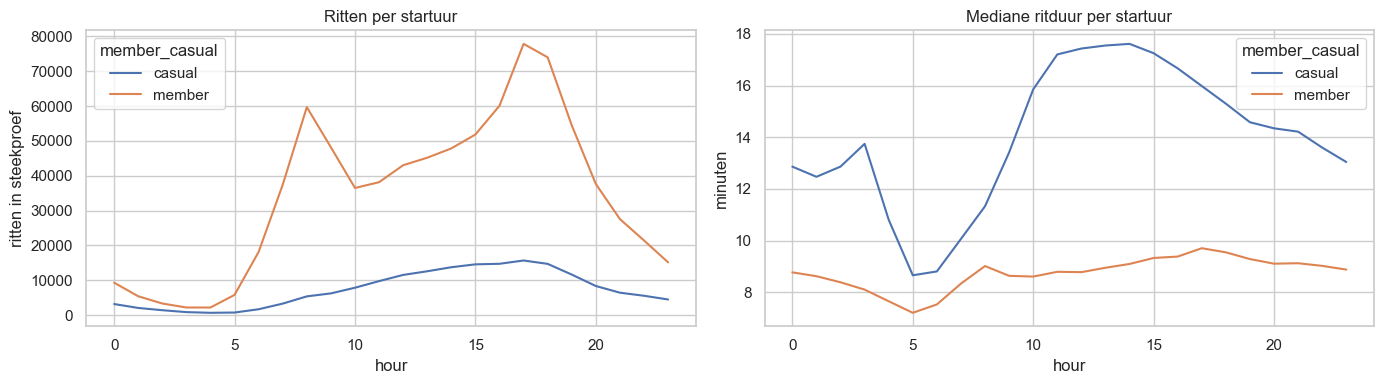

In [10]:
trips["hour"] = trips.started_at.dt.hour
hourly = trips.groupby(["hour", "member_casual"], observed=True).agg(
    rides=("ride_id", "size"), median_minutes=("duration_minutes", "median")
).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.lineplot(data=hourly, x="hour", y="rides", hue="member_casual", ax=axes[0])
sns.lineplot(data=hourly, x="hour", y="median_minutes", hue="member_casual", ax=axes[1])
axes[0].set(title="Ritten per startuur", ylabel="ritten in steekproef")
axes[1].set(title="Mediane ritduur per startuur", ylabel="minuten")
plt.tight_layout()
display(hourly.head())

## Aggregatie 2 — weekritme

Weekdag wordt geordend, zodat alfabetische sortering geen misleidend patroon maakt.

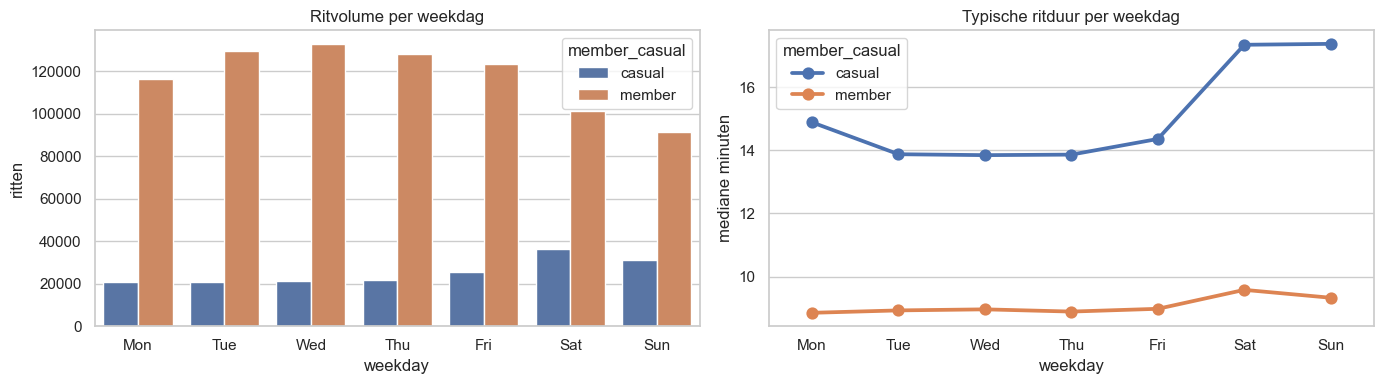

In [11]:
order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
trips["weekday"] = pd.Categorical(trips.started_at.dt.day_name().str[:3], order, ordered=True)
daily = trips.groupby(["weekday", "member_casual"], observed=True).agg(
    rides=("ride_id", "size"), median_minutes=("duration_minutes", "median")
).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=daily, x="weekday", y="rides", hue="member_casual", ax=axes[0])
sns.pointplot(data=daily, x="weekday", y="median_minutes", hue="member_casual", ax=axes[1])
axes[0].set(title="Ritvolume per weekdag", ylabel="ritten")
axes[1].set(title="Typische ritduur per weekdag", ylabel="mediane minuten")
plt.tight_layout()

## Aggregatie 3 — stations

Alleen stations met minstens 500 ritten worden voor mediane duur gerangschikt; kleine groepen leveren instabiele extremen.

,start_station_id,start_station_name,rides,median_minutes,casual_share
3277,6140.05,W 21 St & 6 Ave,2840,7.585392,0.113380
3163,5905.12,Broadway & E 14 St,2189,7.860167,0.169941
2834,5329.03,West St & Chambers St,2176,15.136892,0.274816
3672,6726.01,11 Ave & W 41 St,2166,9.431583,0.161588
3297,6173.08,Broadway & W 25 St,2165,9.441050,0.197229
3164,5905.14,University Pl & E 14 St,2157,7.800783,0.157163
3428,6364.07,6 Ave & W 33 St,2139,8.837200,0.187938
3729,6822.09,1 Ave & E 68 St,2131,11.567767,0.112623
3410,6331.01,W 31 St & 7 Ave,2055,8.477650,0.171776
3313,6197.08,E 33 St & 1 Ave,1995,9.090633,0.141353


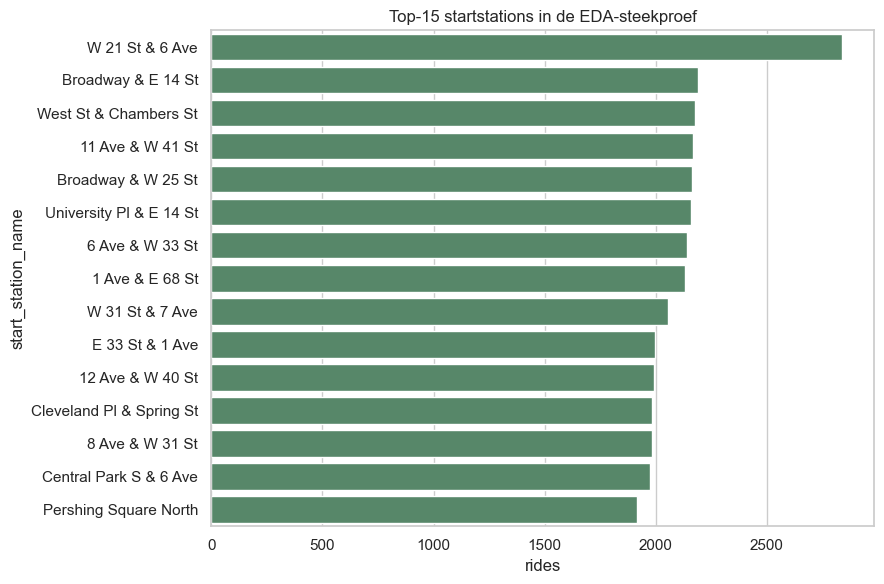

In [12]:
stations = trips.groupby(["start_station_id", "start_station_name"], observed=True).agg(
    rides=("ride_id", "size"), median_minutes=("duration_minutes", "median"),
    casual_share=("member_casual", lambda s: (s == "casual").mean()),
).reset_index()
stable = stations.query("rides >= 500").nlargest(15, "rides")
plt.figure(figsize=(9, 6))
sns.barplot(data=stable, y="start_station_name", x="rides", color="#4f8f67")
plt.title("Top-15 startstations in de EDA-steekproef")
plt.tight_layout()
display(stations.sort_values("rides", ascending=False).head(20))

## Verdeling en outliers

De rechterstaart motiveert MAE en een log-getransformeerde target bij modelleren. De grens van 180 minuten is een vooraf gedocumenteerde plausibiliteitsregel, geen op de testscore afgestemde keuze.

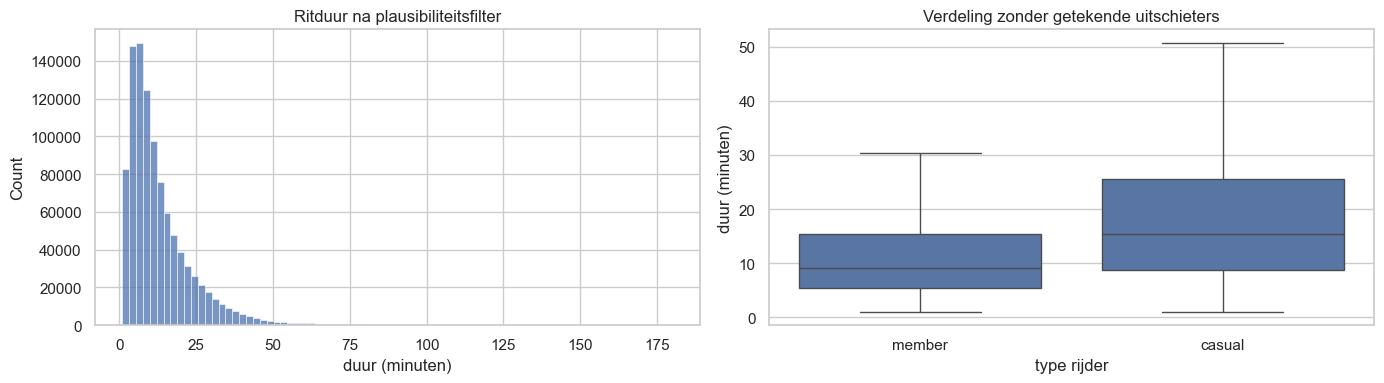

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(trips.duration_minutes, bins=80, ax=axes[0])
sns.boxplot(data=trips, x="member_casual", y="duration_minutes", showfliers=False, ax=axes[1])
axes[0].set(xlabel="duur (minuten)", title="Ritduur na plausibiliteitsfilter")
axes[1].set(xlabel="type rijder", ylabel="duur (minuten)", title="Verdeling zonder getekende uitschieters")
plt.tight_layout()

## Interpretatiechecklist

Vul na uitvoering concrete getallen in: periode en N, grootste piekuren, member/casual-verschil, missings, cleaning-impact en beperkingen. Formuleer associaties; deze observationele data ondersteunen geen causale claims.